In [ ]:
import torch
from torch import nn

#### 2.1.5 mixed precision accumulation: 混合精度累加 

In [ ]:
s = torch.tensor(0, dtype=torch.float32)
for i in range(1000):
    s += torch.tensor(0.01, dtype=torch.float32)
print(s)

s = torch.tensor(0, dtype=torch.float16)
for i in range(1000):
    s += torch.tensor(0.01, dtype=torch.float16)
print(s)

s = torch.tensor(0, dtype=torch.float32)
for i in range(1000):
    s += torch.tensor(0.01, dtype=torch.float16)
print(s)

s = torch.tensor(0, dtype=torch.float32)
for i in range(1000):
    x = torch.tensor(0.01, dtype=torch.float16)
    s += x.type(torch.float32)
print(s)

#### 2.1.5 benchmarking mixed precision: 基准测试混合精度 

In [ ]:
class ToyModel(nn.Module):
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.fc1 = nn.Linear(in_features, 10, bias=False)
        self.ln = nn.LayerNorm(10)
        self.fc2 = nn.Linear(10, out_features, bias=False)
        self.relu = nn.ReLU()

    def forward(self, x):
        print("input:", x.dtype)
        x = self.fc1(x)
        print("linear1:", x.dtype)
        x = self.relu(x)
        print("relu:", x.dtype)
        x = self.ln(x)
        print("layernorm:", x.dtype)
        x = self.fc2(x)
        print("linear2:(output):", x.dtype)
        return x

In [ ]:
device = torch.device("mps")

model = ToyModel(4, 8).to(device)
inputs = torch.rand((2, 4), dtype=torch.float32, device=device)

print("模型设备：", next(model.parameters()).device)
print("输入设备：", inputs.device)

with torch.autocast("mps", dtype=torch.float16):
    logits = model(inputs)

print("Logits：", logits.dtype)
# 退出 autocast 只会停止自动选择算子精度，不会把已有 Tensor 自动转换回 FP32。

In [ ]:
import torch
from torch import nn

x = torch.randn(4, 512, 2560, requires_grad=True)

class RMSNorm(nn.Module):
    def __init__(self, hidden_size: int, eps: float = 1e-5, device=None):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(hidden_size, device=device))
        self.eps = eps
        
    def forward(self, x):
        rms = torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        x = x * rms
        return self.weight * x

def pack_hook(t):
    shape, dtype, grad_fn = t.shape, t.dtype, t.grad_fn
    print(f"Saving residual: {shape=}, {dtype=}, {grad_fn=}")
    return t

def unpack_hook(t):
    shape, dtype, grad_fn = t.shape, t.dtype, t.grad_fn
    print(f"Loading residual: {shape=}, {dtype=}, {grad_fn=}")
    return t

In [ ]:
ln = RMSNorm(x.shape[-1])

with torch.autograd.graph.saved_tensors_hooks(pack_hook, unpack_hook):
    y = ln(x)
    y.sum().backward()

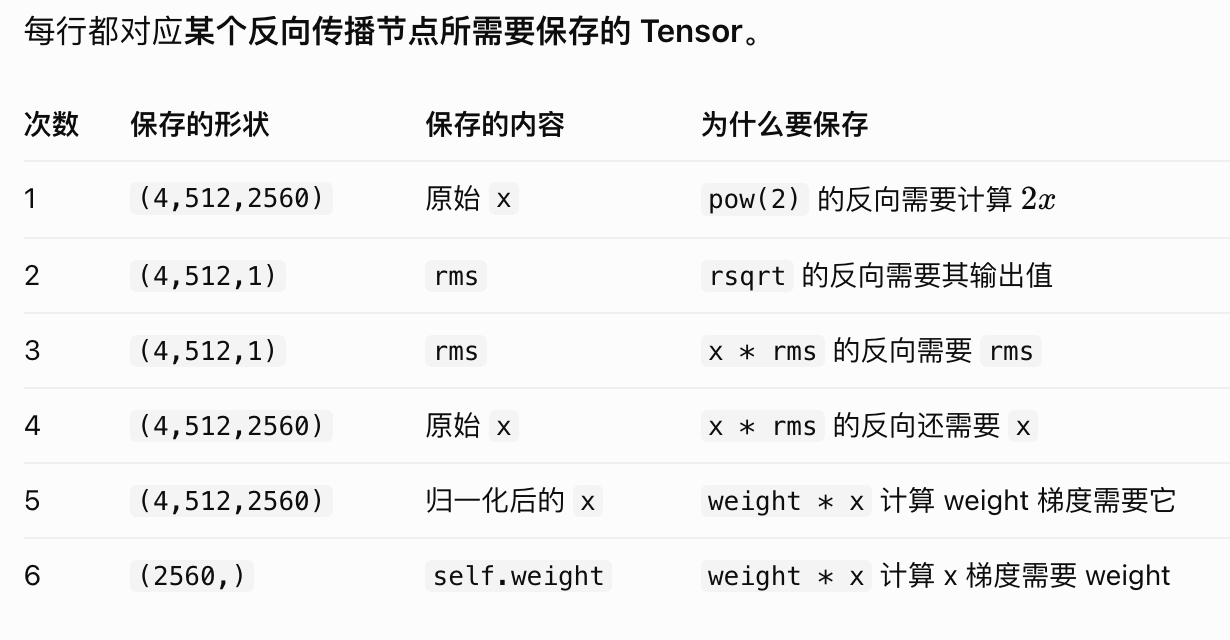

In [ ]:
ln = torch.compile(RMSNorm(x.shape[-1]))

with torch.autograd.graph.saved_tensors_hooks(pack_hook, unpack_hook):
    y = ln(x)
    y.sum().backward()

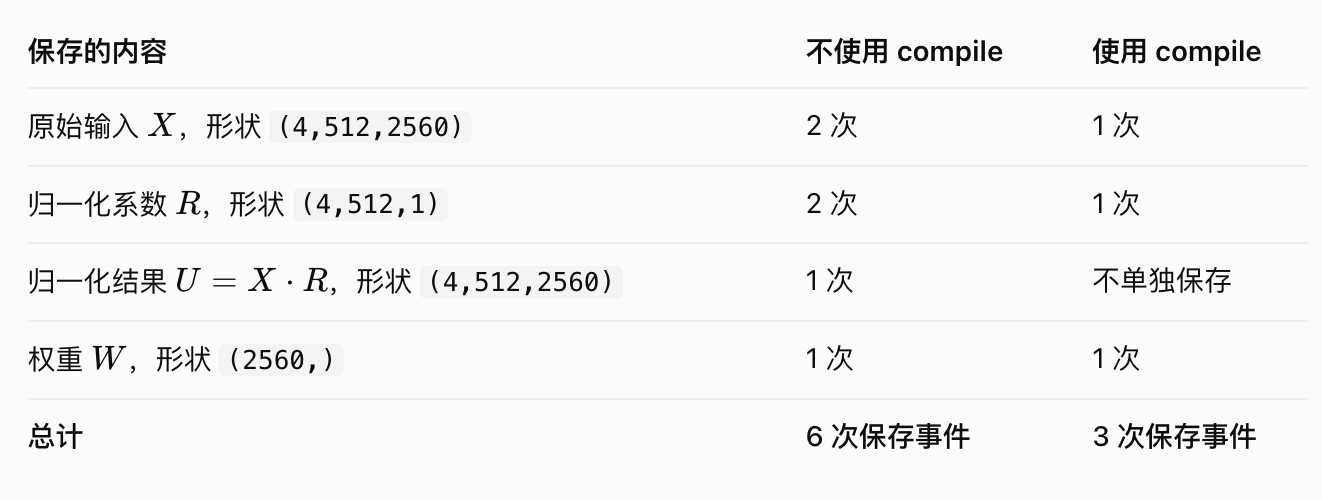

In [ ]:
import torch
from torch import nn
from cs336_basics.model import RotaryEmbedding, TransformerBlock

# num_layers for this model is 32
d_model, d_ff, num_heads, context_length = 2560, 10240, 16, 2048
block = TransformerBlock(d_model=d_model, d_ff=d_ff, num_heads=num_heads,
positional_encoder=RotaryEmbedding(dim=d_model // num_heads, context_length=context_length))

# Fuse as much torch.compile will allow
block = torch.compile(block, fullgraph=True)
x = torch.randn((4, context_length, d_model), requires_grad=True)

# Now logs the number of bytes saved
total_size_bytes = 0
def pack_hook(t):
    if isinstance(t, torch.nn.Parameter): # Skip logging parameters to avoid double counting
        return t
    
    global total_size_bytes
    shape, dtype, grad_fn = t.shape, t.dtype, t.grad_fn
    total_size_bytes += t.numel() * t.element_size()
    print(f"Saving residual: {shape=}, {dtype=}, {grad_fn=}")
    return t


In [ ]:
# Run forward pass, saving for backward
with torch.autograd.graph.saved_tensors_hooks(pack_hook, unpack_hook):
    y = block(x)

print(f"Total size of saved tensors in single TransformerBlock: {total_size_bytes / (1024**2):.2f} MiB")
torch.cuda.empty_cache()


In [ ]:
def four_blocks(x):
    x = block(x)
    x = block(x)
    x = block(x)
    x = block(x)
    return x
with torch.autograd.graph.saved_tensors_hooks(pack_hook, unpack_hook):
    y = four_blocks(x)
print(f"Total size of saved tensors in four TransformerBlocks: {total_size_bytes / (1024**2):.2f} MiB")

In [ ]:
from torch.utils.checkpoint import checkpoint
def two_blocks(x):
    x = block(x)
    x = block(x)
    return x

def four_blocks_checkpoint(x):
    # checkpoint throws out all the saved tensors until the backward pass
    # when getting to the checkpointed block in the backward pass,
    # it reruns a forward pass to produce the saved tensors,
    # then completes normal backward pass.
    x = checkpoint(two_blocks, x, use_reentrant=False)
    x = checkpoint(two_blocks, x, use_reentrant=False)
    return x

with torch.autograd.graph.saved_tensors_hooks(pack_hook, unpack_hook):
    y = four_blocks_checkpoint(x)

print(f"Total size of saved tensors in four TransformerBlocks with checkpointing:{total_size_bytes / (1024**2):.2f} MiB")

优化计算性能的方法：
1. 计算受限优化：改进算法（Flash Attention）、更快的计算单元（Triton）、减少浮点运算量（降低精度）
2. 显存受限优化：算子融合、重计算、分块计算、降低精度

### 5 DDP

#### 5.1 PyTorch 中的单节点分布式通信

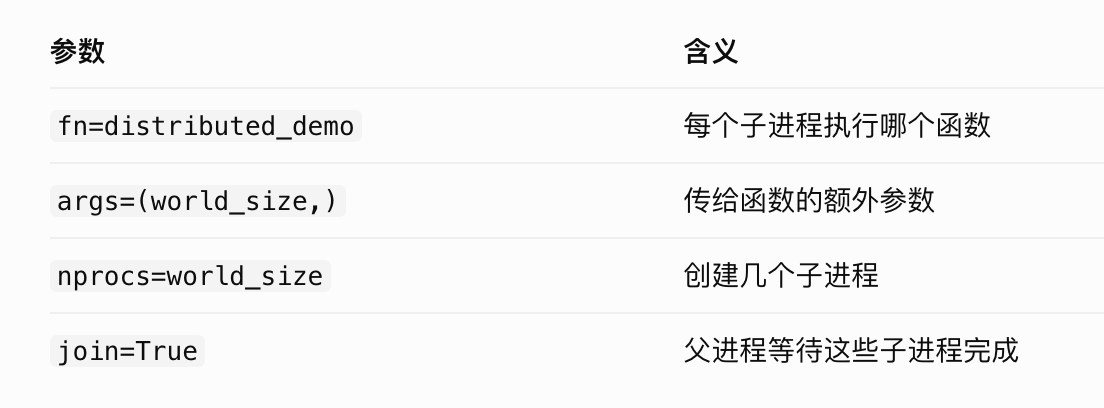

In [ ]:
import os
import torch
import torch.distributed as dist
import torch.multiprocessing as mp

def setup(rank, world_size):
    os.environ["MASTER_ADDR"] = "localhost"
    os.environ["MASTER_PORT"] = "29500"
    dist.init_process_group("gloo", rank=rank, world_size=world_size)

def distributed_demo(rank, world_size):
    setup(rank, world_size)
    data = torch.randint(0, 10, (3,))
    print(f"rank {rank} data (before all-reduce): {data}")
    dist.all_reduce(data, async_op=False)
    print(f"rank {rank} data (after all-reduce): {data}")

if __name__ == "__main__":
    world_size = 4
    mp.spawn(fn=distributed_demo, args=(world_size, ), nprocs=world_size, join=True)

In [3]:
# nvidia-smi -L

import os
import torch

print("CUDA available:", torch.cuda.is_available())
print("Visible devices:", os.environ.get("CUDA_VISIBLE_DEVICES"))
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"cuda:{i} -> {torch.cuda.get_device_name(i)}")

CUDA available: False
Visible devices: None
GPU count: 0


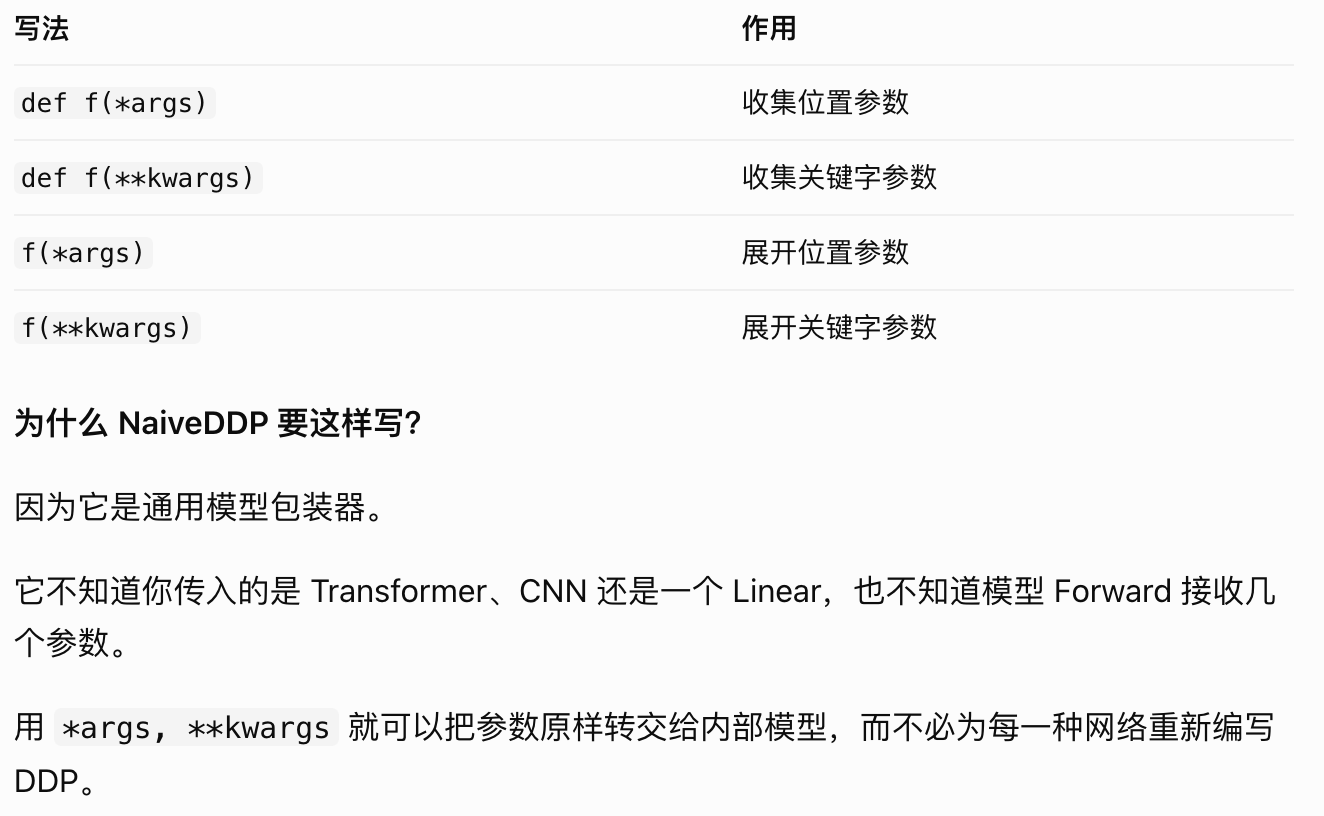

In [4]:
sizes = [8, 6, 5, 3]
world_size = 2

loads = [0] * world_size
owners = []

for size in sizes:
    owner = min(
        range(world_size),
        key=lambda r: loads[r],
    )

    owners.append(owner)
    loads[owner] += size

print("Owners:", owners)
print("Loads:", loads)

Owners: [0, 1, 1, 0]
Loads: [11, 11]


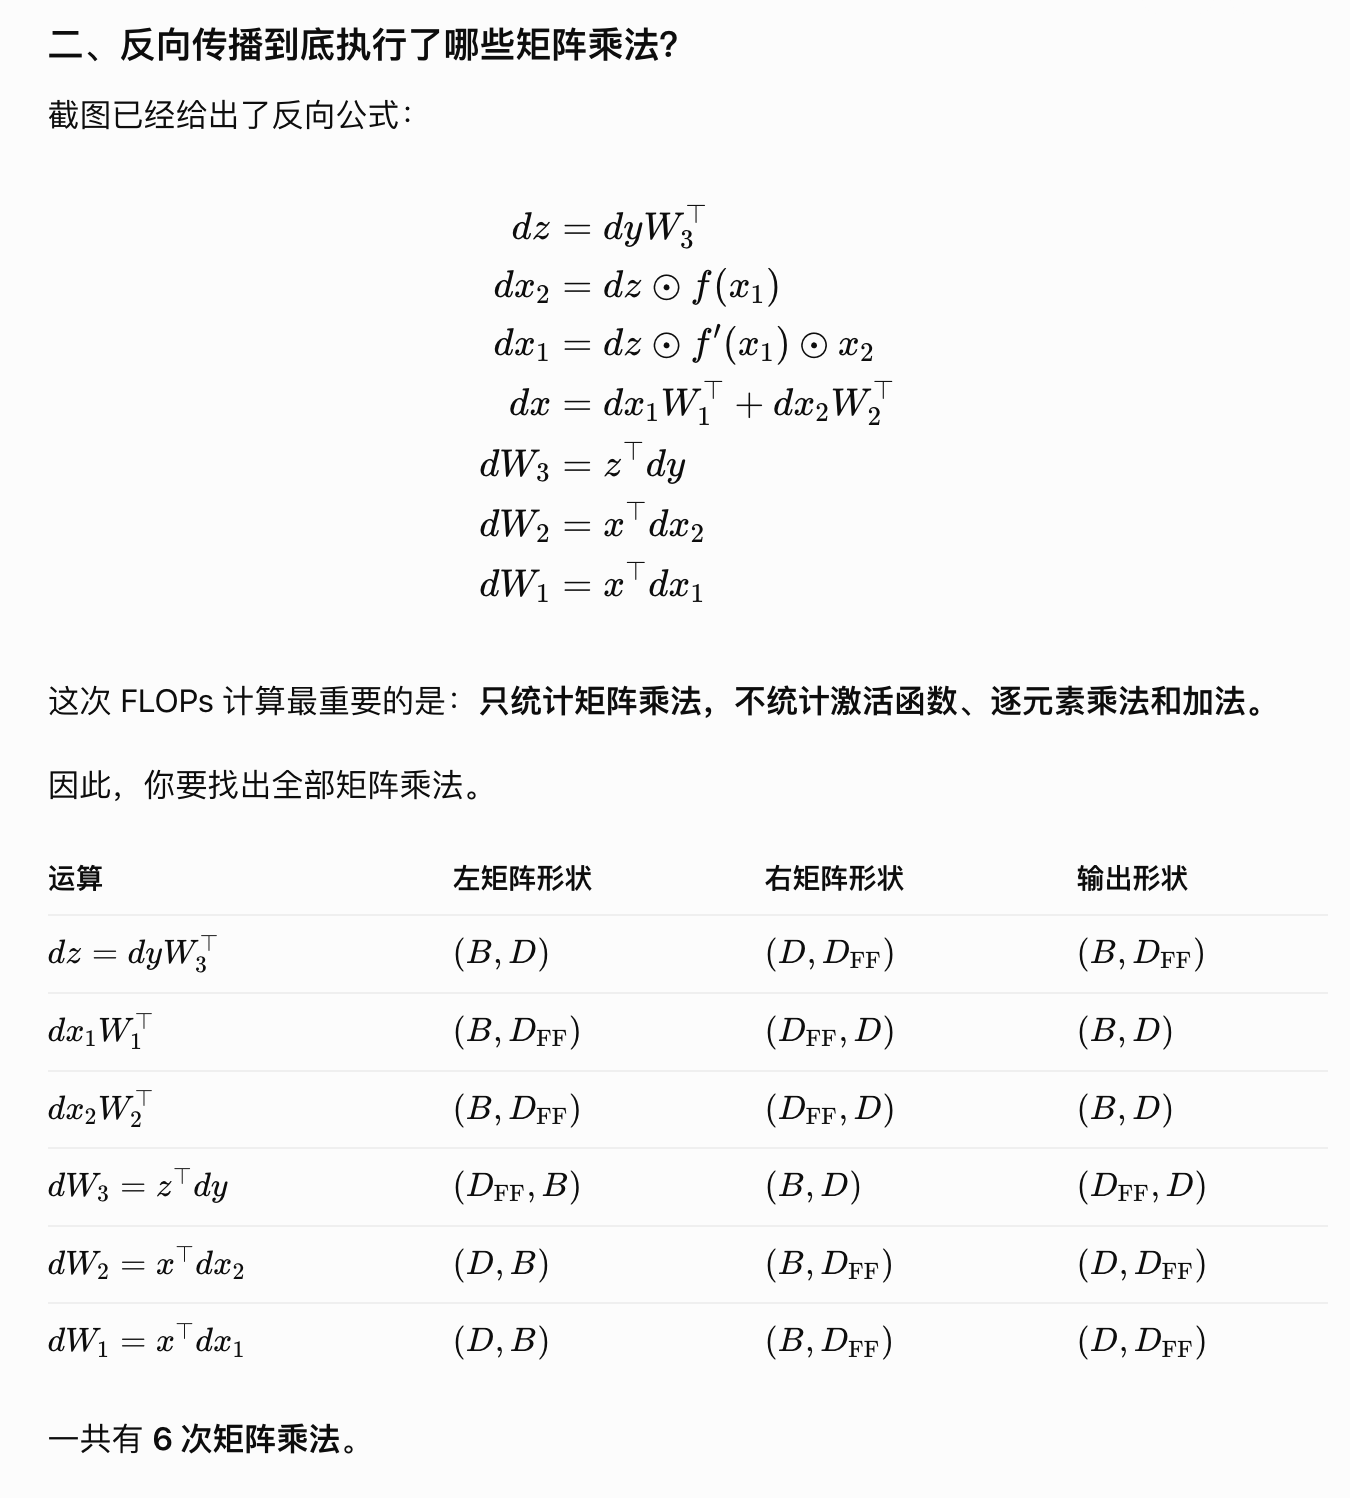